# EN3160 Assignment 1 - Intensity Transformations and Neighborhood Filtering
**D. P. Heshan Ranasinghe | Index: [ADD INDEX] | [GitHub](https://github.com/DPHeshanRanasinghe)**

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

IMAGE_DIR = Path("images")
plt.rcParams.update({"font.size": 8, "figure.dpi": 130, "savefig.bbox": "tight"})

## 1. Piecewise intensity transformation
A 256-level lookup table was formed by linearly interpolating between ordered **(input, output)** breakpoints. The supplied example and two gentler alternatives were tested; the balanced curve was selected for the final image.

In [2]:
def intensity_transform(im, breakpoints):
    """Apply a piecewise-linear mapping to an 8-bit image."""
    image = np.asarray(im)
    points = np.asarray(breakpoints, dtype=np.float32)
    if image.dtype != np.uint8:
        raise TypeError("im must be an 8-bit image")
    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError("breakpoints must have shape (n, 2)")
    if np.any(np.diff(points[:, 0]) <= 0):
        raise ValueError("input breakpoints must be strictly increasing")
    levels = np.arange(256, dtype=np.float32)
    lut = np.interp(levels, points[:, 0], points[:, 1])
    lut = np.clip(np.rint(lut), 0, 255).astype(np.uint8)
    return lut[image]

candidates = {
    "Given example": np.array([[0, 0], [50, 50], [100, 150], [150, 255], [255, 255]]),
    "Gentle": np.array([[0, 0], [40, 50], [90, 110], [140, 165], [200, 225], [255, 255]]),
    "Balanced": np.array([[0, 0], [35, 50], [85, 120], [130, 175], [190, 230], [255, 255]]),
}
selected_name = "Balanced"

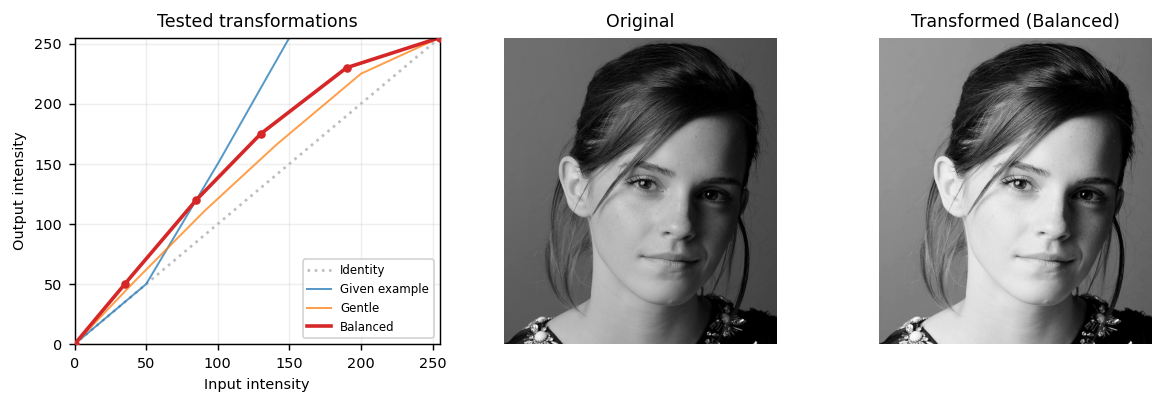

Mean: 92.3 -> 122.2 | Standard deviation: 56.1 -> 67.8


In [3]:
gray = cv2.imread(str(IMAGE_DIR / "q01_portrait_intensity_transform.jpeg"), cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError("Question 1 image could not be loaded")
results = {name: intensity_transform(gray, bp) for name, bp in candidates.items()}
selected = results[selected_name]

fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.0), constrained_layout=True)
levels = np.arange(256)
axes[0].plot(levels, levels, color="0.75", linestyle=":", label="Identity")
for name, bp in candidates.items():
    style = {"linewidth": 2.0, "color": "#d62728"} if name == selected_name else {"linewidth": 1.1, "alpha": 0.75}
    axes[0].plot(levels, np.interp(levels, bp[:, 0], bp[:, 1]), label=name, **style)
axes[0].scatter(candidates[selected_name][:, 0], candidates[selected_name][:, 1], s=14, color="#d62728", zorder=3)
axes[0].set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title="Tested transformations")
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=6.5, loc="lower right")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Original")
axes[2].imshow(selected, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"Transformed ({selected_name})")
for ax in axes[1:]:
    ax.axis("off")
plt.show()
print(f"Mean: {gray.mean():.1f} -> {selected.mean():.1f} | Standard deviation: {gray.std():.1f} -> {selected.std():.1f}")

**Interpretation and discussion.** The balanced breakpoints increased the mean intensity from **92.3 to 122.2** and the standard deviation from **56.1 to 67.8**. Thus, shadow and midtone separation on the face improved while the endpoints $(0,0)$ and $(255,255)$ retained the available intensity range. The supplied curve was more aggressive and pushed many bright pixels toward saturation, whereas the gentle curve produced less visible improvement; the selected curve gave the best compromise between facial detail, contrast, and highlight preservation.